# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [1]:
%load_ext autoreload
%autoreload 2

%pip install torch torchvision kagglehub opencv-python tensorflow tensorflow.keras

# pytorch
import torch

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_dataset = os.path.join(lis_path, "LIS-fingerspelling-dataset")
asl_dataset = os.path.join(asl_path, "asl_alphabet_train/asl_alphabet_train")

Italian Sing Language dataset path: /home/michelangelo/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /home/michelangelo/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## LIS model

In [4]:
from train import train_and_save
from plotter import plot_loss, plot_acc

from dataclasses import dataclass

@dataclass
class TrainConfig:
    train_threshold: float = 0.85
    epochs: int = 25
    batch_size: int = 32
    learning_rate: float = 0.01
    
    
config = TrainConfig()

In [14]:
from model import SignLanguageCNN
path_params = "models/lis_model.pth"

# If you want to save the paramenters, change output_path with path_params
lis_history = train_and_save(dataset=lis_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=None)

Epoch 01/25 | train_loss=3.0876, train_acc=0.0552 | test_loss=3.0797, test_acc=0.0532
Epoch 02/25 | train_loss=3.0747, train_acc=0.0668 | test_loss=3.0564, test_acc=0.1607
Epoch 03/25 | train_loss=3.0222, train_acc=0.1154 | test_loss=2.8889, test_acc=0.1975


KeyboardInterrupt: 

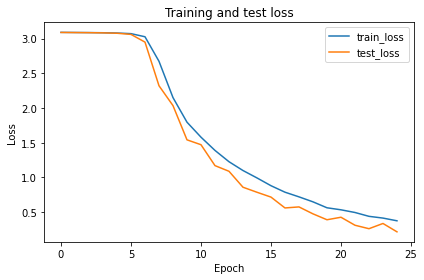

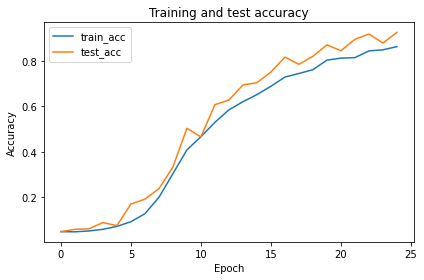

In [6]:
plot_loss(lis_history)
plot_acc(lis_history)

In [10]:
path = "models"
dir_list = os.listdir(path)
print(dir_list)

['asl_model.pth', 'lis_model.pth', 'resnet_lis_model', 'mnv2_lis_model.pth']


[W702 22:54:52.146662333 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W702 22:54:53.389335406 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


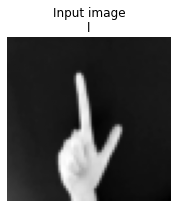

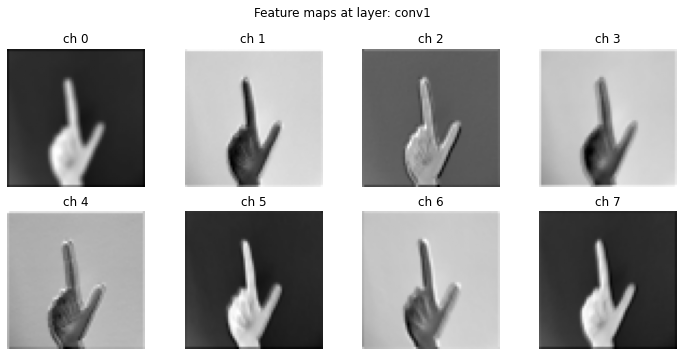

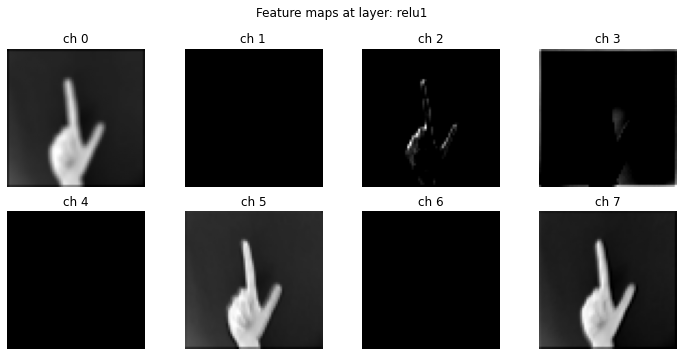

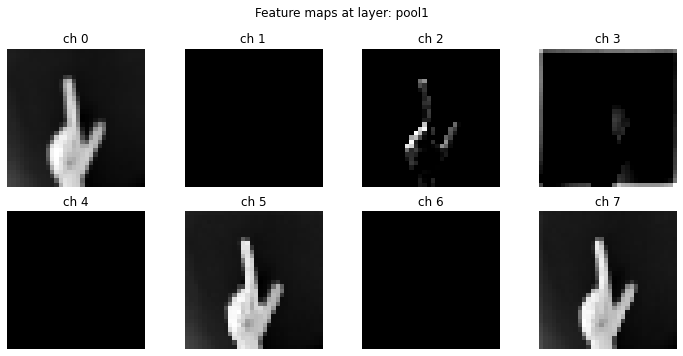

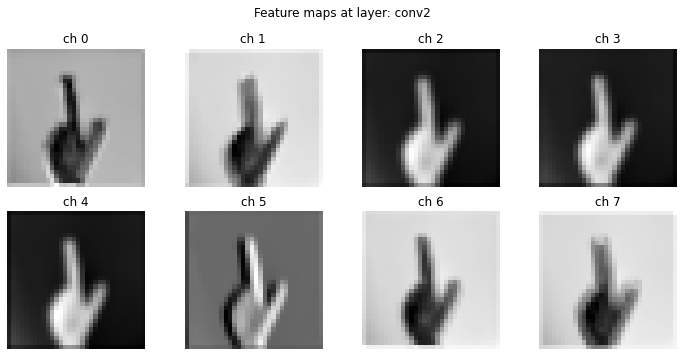

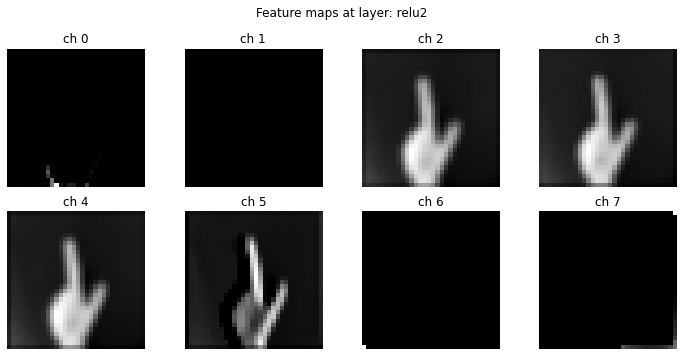

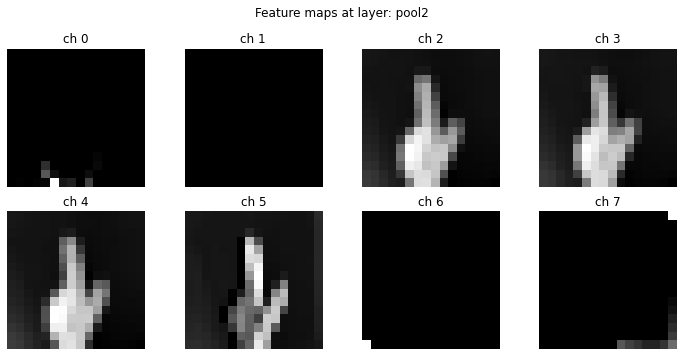

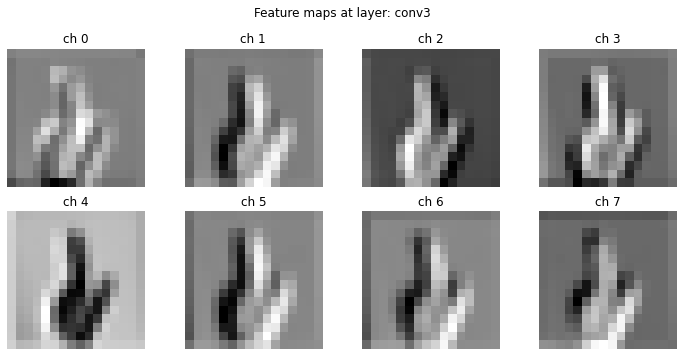

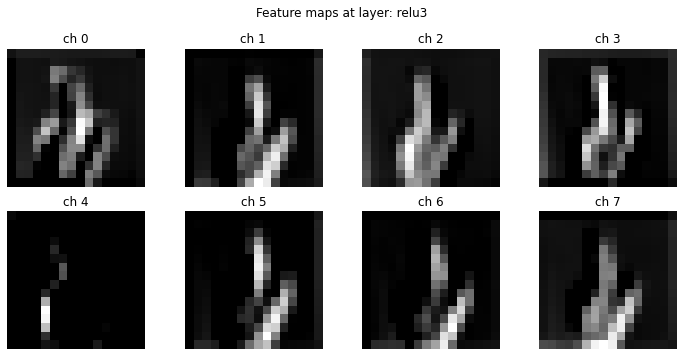

[W702 22:56:17.281897123 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W702 22:56:17.293272361 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


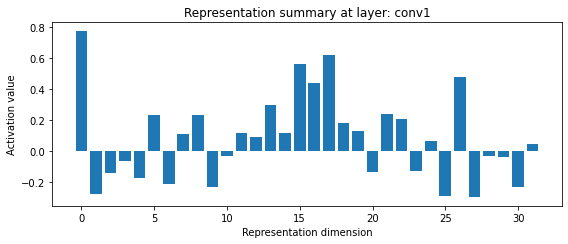

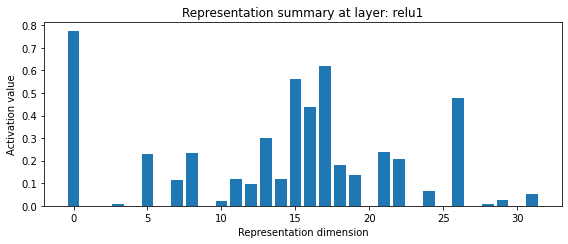

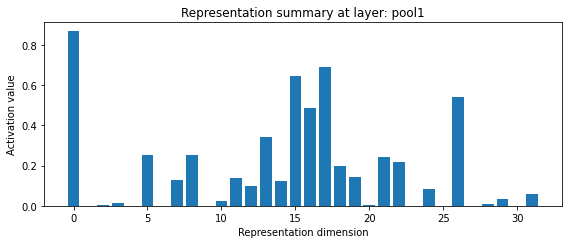

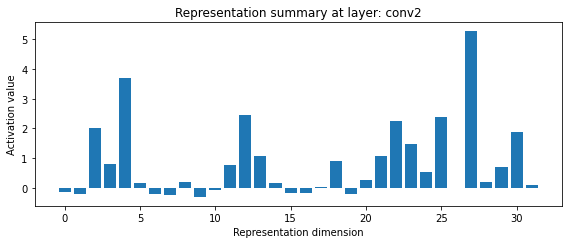

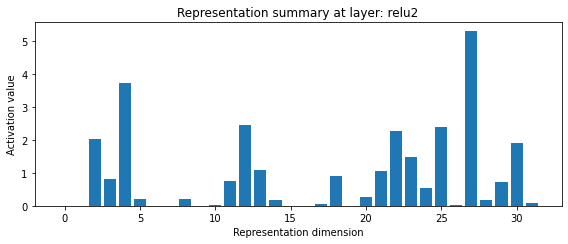

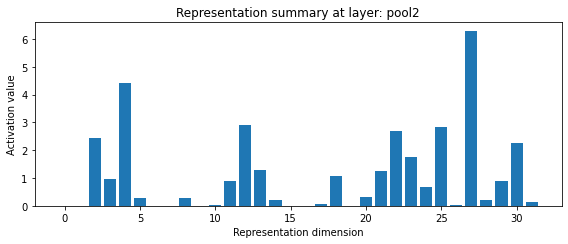

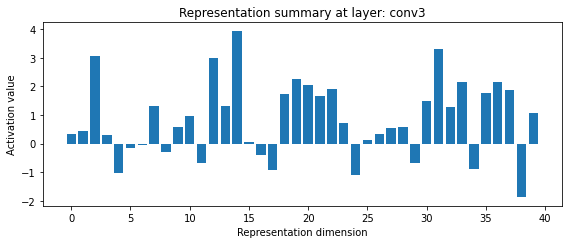

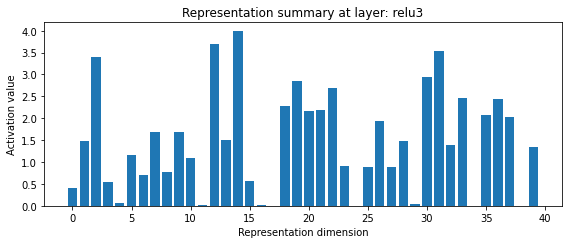

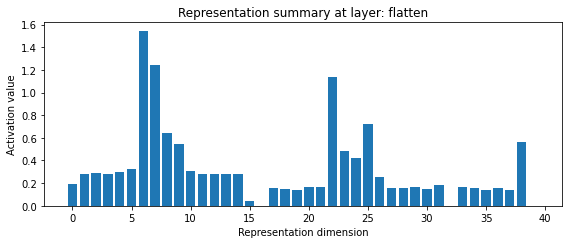

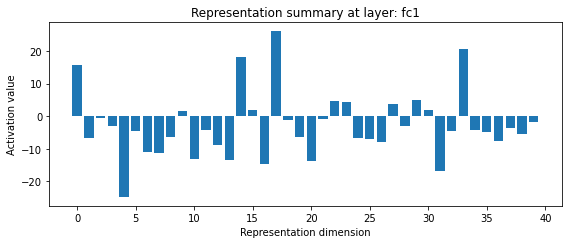

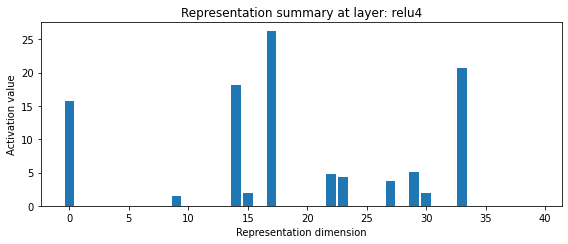

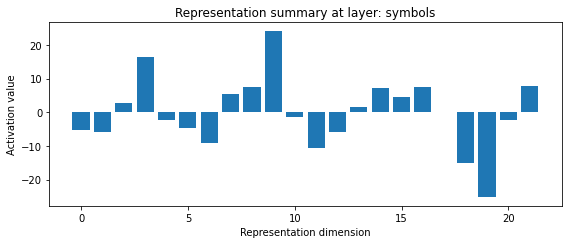

In [ ]:
# NEED TO BE INTEGRATED IN SOME WAY

from representation import show_feature_maps, show_representation_summaries
import torchvision.transforms as transforms
from model import SignLanguageCNN
from torch.utils.data import DataLoader
from dataset_build import get_dataset
model_dir = "models"

lis_classes = {0: 'a', 1: 'b', 2: 'c', 3: 'd', 4: 'e', 5: 'f', 6: 'h', 7: 'i', 8: 'k', 9: 'l', 10: 'm', 11: 'n', 12: 'o', 13: 'p', 14: 'q', 15: 'r', 16: 't', 17: 'u', 18: 'v', 19: 'w', 20: 'x', 21: 'y'}

lis_model = SignLanguageCNN(len(lis_classes))
lis_model = torch.load(os.path.join(model_dir, "lis_model.pth"), weights_only=False)
lis_model.eval()

img_size = (64,64)
    
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(img_size),
    transforms.ToTensor(),
])
    
target_transform = transforms.Lambda(
    lambda y: torch.tensor(y)
)
    
train, test = get_dataset(lis_dataset, config.train_threshold, transform, target_transform)
num_classes = len(train.label_to_idx)

test_loader = DataLoader(
            test,
            config.batch_size,
            shuffle=True,
    )

class_names = train.get_classes()

show_feature_maps(lis_model, test_loader, class_names, device)
show_representation_summaries(lis_model, test_loader, device)

## ASL model

In [8]:
path_params = "models/asl_model.pth"

# If you want to save the paramenters, change output_path with path_params
asl_history = train_and_save(dataset=asl_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=None)

Epoch 01/25 | train_loss=3.1095, train_acc=0.1119 | test_loss=2.3767, test_acc=0.2717
Epoch 02/25 | train_loss=1.5613, train_acc=0.4969 | test_loss=0.9739, test_acc=0.6624
Epoch 03/25 | train_loss=0.6418, train_acc=0.7774 | test_loss=0.5048, test_acc=0.8153
Epoch 04/25 | train_loss=0.3386, train_acc=0.8829 | test_loss=0.3433, test_acc=0.8826
Epoch 05/25 | train_loss=0.2122, train_acc=0.9271 | test_loss=0.2706, test_acc=0.9020
Epoch 06/25 | train_loss=0.1454, train_acc=0.9516 | test_loss=0.2022, test_acc=0.9306
Epoch 07/25 | train_loss=0.0984, train_acc=0.9674 | test_loss=0.1638, test_acc=0.9441
Epoch 08/25 | train_loss=0.0796, train_acc=0.9736 | test_loss=0.1103, test_acc=0.9634
Epoch 09/25 | train_loss=0.0638, train_acc=0.9783 | test_loss=0.1127, test_acc=0.9623
Epoch 10/25 | train_loss=0.0589, train_acc=0.9818 | test_loss=0.0755, test_acc=0.9757
Epoch 11/25 | train_loss=0.0398, train_acc=0.9874 | test_loss=0.0730, test_acc=0.9767
Epoch 12/25 | train_loss=0.0329, train_acc=0.9897 | te

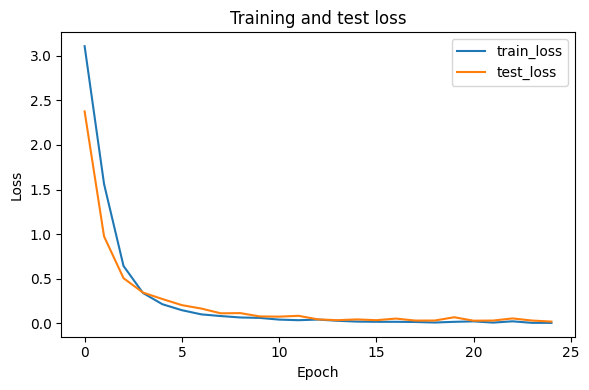

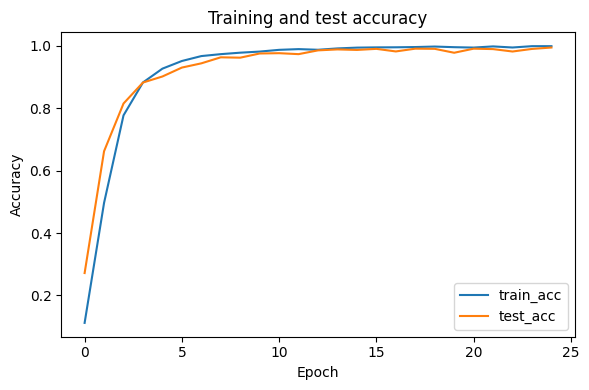

In [9]:
plot_loss(asl_history)
plot_acc(asl_history)

## ResNET50

In [ ]:
from torchvision.models import resnet50
path_params = "models/LIS_resnet50_model.pth"

# If you want to save the parameters, change output_path with path_params
resnet_history_LIS = train_and_save(dataset=lis_dataset, model_class=resnet50, config=config, device=device, output_path=path_params)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/michelangelo/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:08<00:00, 12.6MB/s]


KeyboardInterrupt: 

In [ ]:
plot_loss(resnet_history_LIS)
plot_acc(resnet_history_LIS)

In [ ]:
path_params = "models/ASL_resnet50_model.pth"

# If you want to save the parameters, change output_path with path_params
resnet_history_ASL = train_and_save(dataset=asl_dataset, model_class=resnet50, config=config, device=device, output_path=path_params)

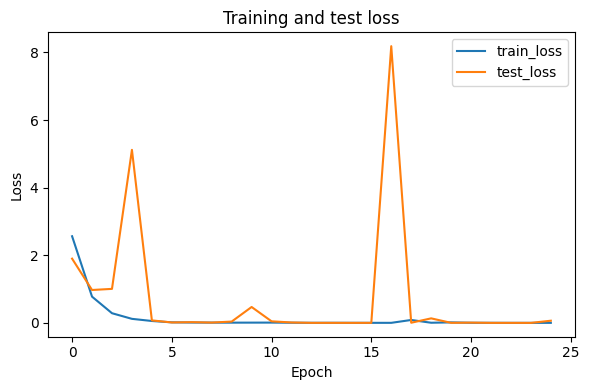

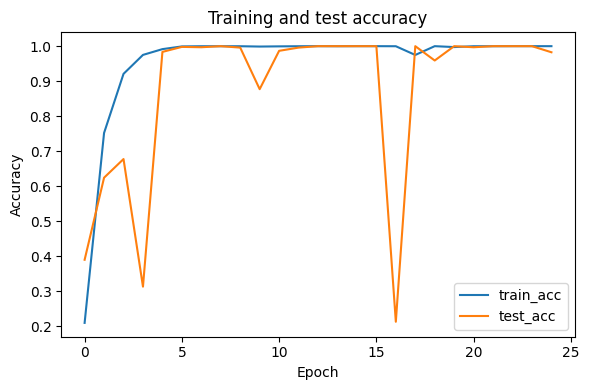

In [ ]:
plot_loss(resnet_history_ASL)
plot_acc(resnet_history_ASL)

## VGG16

In [ ]:
from torchvision.models import vgg16
path_params = "models/LIS_vgg16_model.pth"

# If you want to save the parameters, change output_path with path_params
vgg16_history_LIS = train_and_save(dataset=lis_dataset, model_class=vgg16, config=config, device=device, output_path=path_params)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /home/michelangelo/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:45<00:00, 12.0MB/s] 


KeyboardInterrupt: 

In [ ]:
plot_loss(vgg16_history_LIS)
plot_acc(vgg16_history_LIS)

In [ ]:
path_params = "models/ASL_vgg16_model.pth"

# If you want to save the parameters, change output_path with path_params
vgg16_history_ASL = train_and_save(dataset=lis_dataset, model_class=vgg16, config=config, device=device, output_path=path_params)

In [ ]:
plot_loss(vgg16_history_ASL)
plot_acc(vgg16_history_ASL)

## MobileNetV2

In [ ]:
#from mobilenetv2 import MobileNetV2
#lis_history = train_and_save(dataset=lis_dataset, model_class=MobileNetV2, config=config, device=device, output_path="mnv2_lis_model.pth")

from torchvision.models import mobilenet_v2
path_params = "models/LIS_mobilenetv2_model.pth"

# If you want to save the parameters, change output_path with path_params
mobilenetv2_history_LIS = train_and_save(dataset=lis_dataset, model_class=mobilenet_v2, config=config, device=device, output_path=path_params)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/michelangelo/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 9.53MB/s]


KeyboardInterrupt: 

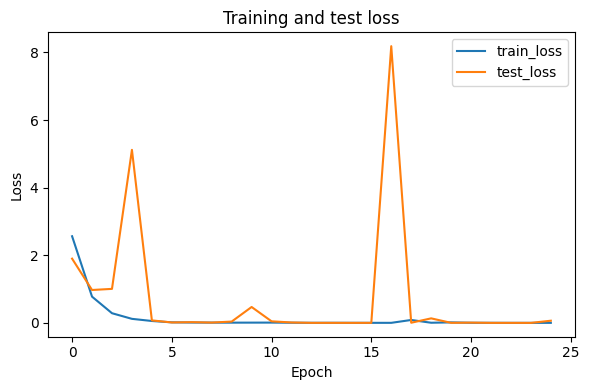

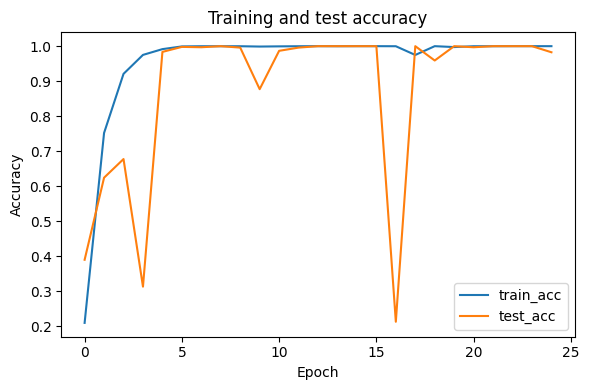

In [ ]:
plot_loss(mobilenetv2_history_LIS)
plot_acc(mobilenetv2_history_LIS)

In [ ]:
path_params = "models/ASL_mobilenetv2_model.pth"

# If you want to save the parameters, change output_path with path_params
mobilenetv2_history_ASL = train_and_save(dataset=asl_dataset, model_class=mobilenet_v2, config=config, device=device, output_path=path_params)

In [ ]:
plot_loss(mobilenetv2_history_ASL)
plot_acc(mobilenetv2_history_ASL)

## Test


In [3]:
from testing import test_camera

lis_idx_to_string = {0: 'a', 1: 'b', 2: 'c', 3: 'd', 4: 'e', 5: 'f', 6: 'h', 7: 'i', 8: 'k', 9: 'l', 10: 'm', 11: 'n', 12: 'o', 13: 'p', 14: 'q', 15: 'r', 16: 't', 17: 'u', 18: 'v', 19: 'w', 20: 'x', 21: 'y'}
asl_idx_to_string = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'J', 10: 'K', 11: 'L', 12: 'M', 13: 'N', 14: 'O', 15: 'P', 16: 'Q', 17: 'R', 18: 'S', 19: 'T', 20: 'U', 21: 'V', 22: 'W', 23: 'X', 24: 'Y', 25: 'Z', 26: 'del', 27: 'nothing', 28: 'space'}


### LIS test with our model

In [ ]:
from model import SignLanguageCNN
test_camera(SignLanguageCNN, "lis_model.pth", lis_idx_to_string)

I0000 00:00:1783012900.244280 12667685 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
W0000 00:00:1783012900.247999 12667692 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783012900.251904 12667693 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


### ASL test with our model

In [ ]:
from model import SignLanguageCNN
test_camera(SignLanguageCNN, "asl_model.pth", asl_idx_to_string)

I0000 00:00:1783013641.794395 12723707 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
I0000 00:00:1783013641.848285 12723707 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1783013641.856736 12723710 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013641.866358 12723710 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013641.915708 12723709 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
E0000 00:00:1783013788.449491 12723708 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITIO

: 

### LIS test with Resnet

In [ ]:
from ResNet import ResNet50
test_camera(ResNet50, "resnet_lis_model", lis_idx_to_string)

### LIS test with MNV2

In [ ]:
from mobilenetv2 import MobileNetV2
test_camera(MobileNetV2, "mnv2_lis_model.pth", lis_idx_to_string)

I0000 00:00:1783013346.304868 12703985 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
I0000 00:00:1783013346.351654 12703985 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1783013346.357571 12703991 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013346.366586 12703993 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013346.402845 12703992 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
E0000 00:00:1783013466.340415 12703986 portable_clearcut_uploader.cc:90] Failed to send to clearcut: INTERNAL: Response

: 